# Итоговый проект: анализ датасета Medical Cost Personal Datasets

Автор проекта: Мальгин Олег, 3 курс

Курс: Python для анализа данных

Источник данных: [Medical Cost Personal Datasets - Kaggle](https://www.kaggle.com/datasets/mirichoi0218/insurance/data)

Исходный файл с данными: `insurance.csv` (предоставляется вместе с проектом)

---

## Содержание

1. [Датасет и описание данных](#1)
2. [Фильтрация, сортировка и создание новых признаков](#2)
3. [Частотные и сводные таблицы](#3)
4. [Пропуски и выбросы](#4)
5. [Описательная статистика](#5)
6. [Сравнение групп и проверка статистической гипотезы](#6)
7. [Визуализация данных](#7)
8. [Корреляционный анализ](#8)
9. [Линейная регрессия](#9)
10. [Итоговые выводы](#10)

Цель работы: провести комплексный анализ данных о персональных медицинских расходах застрахованных лиц из США: описать структуру датасета, выполнить преобразования и очистку данных, построить частотные и сводные таблицы, исследовать пропуски и выбросы, рассчитать описательные статистики, проверить статистическую гипотезу, построить содержательные визуализации, исследовать корреляции и построить модель линейной регрессии для прогнозирования годовых медицинских расходов (`charges`).


<a id="1"></a>
# 1. Датасет и описание данных

Датасет Medical Cost Personal Datasets размещён на Kaggle и содержит информацию о застрахованных лицах в США: их демографические характеристики, индекс массы тела, статус курения, регион проживания и индивидуальные годовые медицинские расходы, выставленные страховщиком (`charges`).

Что делаем: загружаем исходный файл `insurance.csv` в `pandas.DataFrame`, показываем первые строки, определяем размер выборки, типы данных признаков и приводим их содержательное описание.

Источник данных: [https://www.kaggle.com/datasets/mirichoi0218/insurance/data](https://www.kaggle.com/datasets/mirichoi0218/insurance/data)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Настройки отображения таблиц и графиков
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
pd.set_option('display.max_columns', None)

Загружаем данные из исходного файла `insurance.csv`, который лежит в одной папке с ноутбуком:

In [2]:
# Загрузка данных в DataFrame
df = pd.read_csv('insurance.csv')

print(f"Количество наблюдений (строк):    {df.shape[0]}")
print(f"Количество признаков (столбцов): {df.shape[1]}")

df.head()

Количество наблюдений (строк):    1338
Количество признаков (столбцов): 7


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
# Общая информация о таблице: типы данных и заполненность столбцов
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


## Описание признаков

Для каждого признака приведём название, содержательное описание и тип данных:

| Признак | Содержательное описание | Тип данных |
|---|---|---|
| `age` | Возраст застрахованного лица, лет | Количественный, `int64` |
| `sex` | Пол застрахованного лица (`female` / `male`) | Категориальный, `object` |
| `bmi` | Индекс массы тела (ИМТ): отношение веса (кг) к квадрату роста (м²) | Количественный, `float64` |
| `children` | Количество детей, покрываемых медицинской страховкой | Количественный, `int64` |
| `smoker` | Статус курения (`yes` / `no`) | Категориальный, `object` |
| `region` | Регион проживания в США (`northeast`, `northwest`, `southeast`, `southwest`) | Категориальный, `object` |
| `charges` | Индивидуальные годовые медицинские расходы по страховке, долл. США - целевая переменная | Количественный, `float64` |

## Соответствие датасета требованиям задания

Проверим, что выбранный датасет подходит под требования итогового проекта:

- Объём выборки: 1338 наблюдений - существенно больше минимально необходимых 100;
- Типы признаков: в данных есть 4 количественных признака (`age`, `bmi`, `children`, `charges`) и 3 категориальных (`sex`, `smoker`, `region`);
- Не временной ряд: в датасете нет даты/времени наблюдения - это набор независимых записей о людях, поэтому хронологический порядок не важен;
- Задача регрессии: целевая переменная `charges` - непрерывная количественная величина, значит возможна постановка задачи линейной регрессии: по возрасту, ИМТ, числу детей и категориальным признакам предсказать размер годовых медицинских расходов.

Вывод по разделу: датасет полностью соответствует требованиям задания. Далее все расчёты и преобразования будем выполнять в pandas, а целевой переменной всего анализа выступит `charges`.


<a id="2"></a>
# 2. Фильтрация, сортировка и создание новых признаков

Что делаем: базовые операции pandas с датасетом. Отбираем подмножества наблюдений по одному и по нескольким условиям, сортируем результаты, а затем создаём два новых признака: бинарный признак через `lambda` и признак возрастной группы через самостоятельно написанную функцию.


## 2.1. Фильтрация по одному условию и сортировка

Отберём наблюдения по одному условию - только курильщиков и отсортируем их по величине медицинских расходов `charges` по убыванию:

In [4]:
# Фильтрация по одному условию: только курильщики
smokers = df[df['smoker'] == 'yes']

# Сортировка результата по расходам по убыванию
smokers_sorted = smokers.sort_values('charges', ascending=False)

print(f"Всего наблюдений в датасете: {len(df)}")
print(f"Курильщиков: {len(smokers_sorted)} "
      f"({len(smokers_sorted) / len(df):.1%} выборки)")

smokers_sorted.head(10)

Всего наблюдений в датасете: 1338
Курильщиков: 274 (20.5% выборки)


,age,sex,bmi,children,smoker,region,charges
543,54,female,47.410,0,yes,southeast,63770.42801
1300,45,male,30.360,0,yes,southeast,62592.87309
1230,52,male,34.485,3,yes,northwest,60021.39897
577,31,female,38.095,1,yes,northeast,58571.07448
819,33,female,35.530,0,yes,northwest,55135.40209
1146,60,male,32.800,0,yes,southwest,52590.82939
34,28,male,36.400,1,yes,southwest,51194.55914
1241,64,male,36.960,2,yes,southeast,49577.66240
1062,59,male,41.140,1,yes,southeast,48970.24760
488,44,female,38.060,0,yes,southeast,48885.13561


Интерпретация результата. В выборке 274 курильщика (20.5% наблюдений). Топ-10 самых дорогих страховых полисов - все у курильщиков, и их расходы (55 000-63 770) многократно превышают медианный уровень расходов по датасету. При этом у всех лидеров высокий ИМТ (30-47) и возраст в основном старше 40 лет - уже на этом шаге видно, что курение в сочетании с лишним весом и возрастом резко увеличивает расходы на медицину.

## 2.2. Фильтрация по нескольким условиям и сортировка

Теперь отберём наблюдения по трём условиям: курильщики старше 50 лет с ИМТ не ниже 30 (ожирение по классификации ВОЗ). Результат отсортируем по расходам и по возрасту:

In [5]:
# Фильтрация по нескольким условиям: курильщики, возраст >= 50, ИМТ >= 30
risk_group = df[(df['smoker'] == 'yes') & (df['age'] >= 50) & (df['bmi'] >= 30)]

# Сортировка: сначала по расходам по убыванию, затем по возрасту по убыванию
risk_group = risk_group.sort_values(['charges', 'age'], ascending=[False, False])

print(f"Наблюдений в группе риска: {len(risk_group)} из {len(df)} "
      f"({len(risk_group) / len(df):.1%})")
print(f"Средние расходы группы риска: {risk_group['charges'].mean():,.2f} долл.")
print(f"Медианные расходы группы риска: {risk_group['charges'].median():,.2f} долл.")
print(f"Средние расходы по всему датасету: {df['charges'].mean():,.2f} долл.")

risk_group.head(10)

Наблюдений в группе риска: 41 из 1338 (3.1%)
Средние расходы группы риска: 46,973.11 долл.
Медианные расходы группы риска: 46,889.26 долл.
Средние расходы по всему датасету: 13,270.42 долл.


,age,sex,bmi,children,smoker,region,charges
543,54,female,47.410,0,yes,southeast,63770.42801
1230,52,male,34.485,3,yes,northwest,60021.39897
1146,60,male,32.800,0,yes,southwest,52590.82939
1241,64,male,36.960,2,yes,southeast,49577.66240
1062,59,male,41.140,1,yes,southeast,48970.24760
175,63,female,37.700,0,yes,southwest,48824.45000
530,57,male,42.130,1,yes,southeast,48675.51770
901,60,male,40.920,0,yes,southeast,48673.55880
281,54,male,40.565,3,yes,northeast,48549.17835
330,61,female,36.385,1,yes,northeast,48517.56315


Интерпретация результата. В группу риска (курильщики 50+ лет с ожирением) попали 41 человек (3.1% выборки), но их средние расходы - около 47 000 долл., то есть примерно в 3.5 раза выше среднего по датасету (13 270 долл.). Это худшие с точки зрения страховщика клиенты, и при ценообразовании их стоило бы идентифицировать отдельно. Сортировка показывает, что расходы внутри группы очень велики и близки друг к другу - почти у всех они превышают 30 000 долл.

## 2.3. Новый бинарный признак с использованием `lambda`

Создадим признак `is_obese` - бинарный индикатор ожирения. По классификации ВОЗ ожирение начинается при ИМТ ≥ 30 кг/м²:

In [6]:
# Бинарный признак ожирения: 1 - ИМТ >= 30 (ожирение), 0 - иначе
df['is_obese'] = df['bmi'].apply(lambda x: 1 if x >= 30 else 0)

print(f"Доля наблюдений с ожирением: {df['is_obese'].mean():.1%}")
df[['bmi', 'is_obese']].head(10)

Доля наблюдений с ожирением: 52.8%


,bmi,is_obese
0,27.900,0
1,33.770,1
2,33.000,1
3,22.705,0
4,28.880,0
5,25.740,0
6,33.440,1
7,27.740,0
8,29.830,0
9,25.840,0


Смысл признака. `is_obese = 1`, если у человека ИМТ ≥ 30 (ожирение по ВОЗ), иначе `0`. Признак переводит непрерывный показатель `bmi` в клинически интерпретируемую категорию и позволит сравнивать расходы людей с ожирением и без него. В выборке ожирение у 52.8% застрахованных - это заметная часть данных.

## 2.4. Новый признак с использованием самостоятельно определённой функции

Определим функцию `get_age_group()` и создадим на её основе признак `age_group` - категорию возрастной группы:

In [7]:
def get_age_group(age):
    # Возвращает название возрастной группы по возрасту
    if age < 30:
        return '18-29'
    elif age < 45:
        return '30-44'
    elif age < 60:
        return '45-59'
    return '60+'


# Применяем функцию к признаку age
df['age_group'] = df['age'].apply(get_age_group)

print("Распределение по возрастным группам:")
print(df['age_group'].value_counts().sort_index())

df[['age', 'age_group']].head(10)

Распределение по возрастным группам:
age_group
18-29    417
30-44    392
45-59    415
60+      114
Name: count, dtype: int64


,age,age_group
0,19,18-29
1,18,18-29
2,28,18-29
3,33,30-44
4,32,30-44
5,31,30-44
6,46,45-59
7,37,30-44
8,37,30-44
9,60,60+


Смысл признака. `age_group` переводит точный возраст в четыре содержательные группы жизненного цикла (молодые взрослые, средний возраст, старший возраст, пожилые). Такой признак удобен для группировки в сводных таблицах и визуализаций, когда пошаговое сравнение по годам возраста избыточно. Исходные данные охватывают возраст 18-64 года, распределение по группам практически равномерное (лишь людей 60+ заметно меньше - 114 из 1338).

Вывод по разделу: операции фильтрации и сортировки позволили выделить наиболее «дорогие» для страховщика сегменты клиентов; созданные признаки `is_obese` и `age_group` будут использоваться далее в сводных таблицах и визуализациях.


<a id="3"></a>
# 3. Частотные и сводные таблицы

Что делаем: строим частотные таблицы для категориальных признаков и сводные таблицы (pivot table) с одним и несколькими признаками группировки и методами агрегирования, чтобы понять структуру выборки и сравнить расходы между группами клиентов.


## 3.1. Частотная таблица категориального признака

Построим частотную таблицу для признака `region` (сортировка по частотам по убыванию) и для признака `smoker` (сортировка по значениям признака по возрастанию):

In [8]:
# Частотная таблица для региона: сортировка по частотам (по убыванию)
region_freq = df['region'].value_counts().to_frame('Частота')
region_freq['Доля, %'] = (df['region'].value_counts(normalize=True) * 100).round(1)
region_freq.index.name = 'region'

print("Частотная таблица признака region (сортировка по частотам):")
display(region_freq)

# Частотная таблица для статуса курения: сортировка по значениям признака
smoker_freq = df['smoker'].value_counts().sort_index().to_frame('Частота')
smoker_freq['Доля, %'] = (df['smoker'].value_counts(normalize=True) * 100).round(1)
smoker_freq.index.name = 'smoker'

print("\nЧастотная таблица признака smoker (сортировка по значениям):")
display(smoker_freq)

Частотная таблица признака region (сортировка по частотам):


,Частота,"Доля, %"
region,,
southeast,364,27.2
southwest,325,24.3
northwest,325,24.3
northeast,324,24.2



Частотная таблица признака smoker (сортировка по значениям):


,Частота,"Доля, %"
smoker,,
no,1064,79.5
yes,274,20.5


Интерпретация. Клиенты распределены по четырём регионам практически равномерно: чаще всего встречается юго-восток (`southeast`) - 364 человека (27.2%), на остальные три региона приходится по 24.2-24.3%. Курильщиков 274 человека - около 20.5% выборки, некурящих 1064 (79.5%), то есть некурящие составляют подавляющее большинство.

## 3.2. Сводная таблица: один признак группировки, один метод агрегирования

Построим сводную таблицу средних расходов по статусу курения:

In [9]:
# Сводная таблица: группировка по smoker, агрегирование - среднее по charges
pivot_simple = df.pivot_table(values='charges', index='smoker', aggfunc='mean')

pivot_simple.columns = ['Средние расходы, долл.']
pivot_simple.index.name = 'Статус курения'
pivot_simple.round(2)

,"Средние расходы, долл."
Статус курения,
no,8434.27
yes,32050.23


Интерпретация. Средние расходы курильщиков (32 050 долл.) в 3.8 раза превышают средние расходы некурящих (8 434 долл.). Курение - самый явный наблюдаемый фактор удорожания медицинских расходов в этом датасете.

## 3.3. Более сложная сводная таблица: несколько признаков группировки и несколько методов агрегирования

Построим сводную таблицу: группировка по возрастной группе и статусу курения, агрегирование - среднее и количество наблюдений:

In [10]:
# Сводная таблица: 2 признака группировки (age_group x smoker), 2 агрегата (mean, count)
pivot_complex = df.pivot_table(
    values='charges',
    index='age_group',
    columns='smoker',
    aggfunc=['mean', 'count']
).round(0)

pivot_complex

mean          count    
smoker          no      yes    no yes
age_group                            
18-29       4419.0  27518.0   331  86
30-44       6945.0  30834.0   301  91
45-59      11872.0  35890.0   345  70
60+        15233.0  40631.0    87  27

Интерпретация. Таблица показывает сразу две закономерности:

1. Эффект возраста: в обеих группах (курильщиков и некурящих) средние расходы растут от младшей группы к старшей: у некурящих от 4 419 до 15 233 долл., у курильщиков от 27 518 до 40 631 долл. - старение увеличивает расходы примерно в 1.5-3.5 раза;
2. Эффект курения: в каждой возрастной группе курильщики платят в 2.7-6.2 раза больше некурящих, причём разрыв максимален в младшей группе (18-29 лет: 27 518 против 4 419 долл., в 6.2 раза) - курение «удорожает» страховку сильнее, чем 40 лет дополнительного возраста у некурящего человека.

Вывод по разделу: частотные таблицы показали сбалансированность выборки по регионам и полу и умеренную долю курильщиков (20.5%); сводные таблицы выявили два ключевых драйвера расходов - курение (рост в 3.8 раза) и возраст (рост в ~1.7 раза от группы 18-29 к группе 60+). Эти факторы обязательно стоит включить в модель регрессии.


<a id="4"></a>
# 4. Пропуски и выбросы

Что делаем: проверяем все признаки на пропуски и дубликаты, исследуем выбросы целевой переменной `charges` и количественного предиктора `bmi` методом межквартильного размаха (правило $1.5 \cdot IQR$), принимаем обоснованные решения об их обработке и формируем очищенный DataFrame `df_clean` для дальнейшего анализа.


## 4.1. Проверка пропусков

Посчитаем количество и долю пропущенных значений в каждом столбце, а также проверим данные на полные дубликаты:

In [11]:
# Количество и доля пропусков по всем признакам
missing = df.isnull().sum().to_frame('Пропусков')
missing['Доля, %'] = (df.isnull().mean() * 100).round(2)
missing.index.name = 'Признак'
print(missing)

# Проверка полных дубликатов
n_dup = df.duplicated().sum()
print(f"\nПолных дубликатов строк: {n_dup}")
if n_dup > 0:
    print("\nСтроки-дубликаты:")
    display(df[df.duplicated(keep=False)])

           Пропусков  Доля, %
Признак                      
age                0      0.0
sex                0      0.0
bmi                0      0.0
children           0      0.0
smoker             0      0.0
region             0      0.0
charges            0      0.0
is_obese           0      0.0
age_group          0      0.0

Полных дубликатов строк: 1

Строки-дубликаты:


,age,sex,bmi,children,smoker,region,charges,is_obese,age_group
195,19,male,30.59,0,no,northwest,1639.5631,1,18-29
581,19,male,30.59,0,no,northwest,1639.5631,1,18-29


In [12]:
# Дубликат - это повторная запись одного и того же человека, удаляем её
df = df.drop_duplicates().reset_index(drop=True)

print(f"Размер датасета после удаления дубликатов: {df.shape[0]} наблюдений")

Размер датасета после удаления дубликатов: 1337 наблюдений


Вывод по пропускам. Пропусков нет ни в одном признаке (0 во всех 7 столбцах исходных данных) - датасет Kaggle предоставляется уже очищенным. Поэтому способы обработки пропусков (удаление строк, заполнение средним/модой и т.п.) применять не требуется. Дополнительно найден 1 полный дубликат (мужчина 19 лет с ИМТ 30.59 из северо-западного региона), который удалён как повторная запись одного клиента: иначе этот человек учитывался бы в статистиках дважды.

## 4.2. Выбросы целевой переменной `charges`

Для поиска выбросов используем метод межквартильного размаха: значение считается выбросом, если оно выходит за границы:

$$x < Q_1 - 1.5 \cdot IQR \quad \text{или} \quad x > Q_3 + 1.5 \cdot IQR, \qquad IQR = Q_3 - Q_1$$

Метод выбран потому, что опирается на устойчивые к выброса квантили (медиану и квартили), а не на среднее и стандартное отклонение, и потому корректно работает для скошенных распределений - а распределение расходов, как увидим ниже, сильно скошено вправо.

Q1 = 4,746.34;  Q3 = 16,657.72;  IQR = 11,911.37
Нижняя граница: -13,120.72
Верхняя граница: 34,524.78

Выбросов по charges: 139 (10.4% наблюдений)


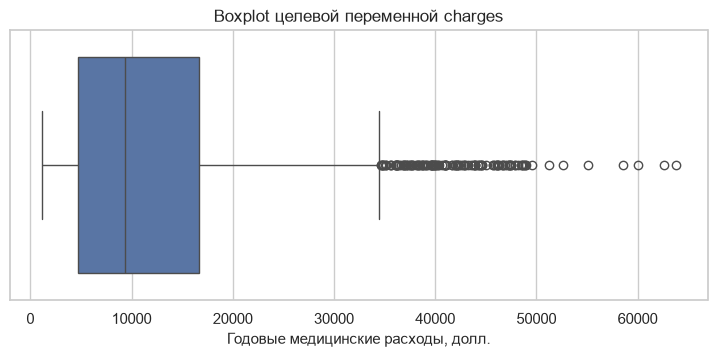

In [13]:
# Расчёт границ по правилу 1.5 * IQR для целевой переменной
q1_ch, q3_ch = df['charges'].quantile([0.25, 0.75])
iqr_ch = q3_ch - q1_ch
lower_ch = q1_ch - 1.5 * iqr_ch
upper_ch = q3_ch + 1.5 * iqr_ch

print(f"Q1 = {q1_ch:,.2f};  Q3 = {q3_ch:,.2f};  IQR = {iqr_ch:,.2f}")
print(f"Нижняя граница: {lower_ch:,.2f}")
print(f"Верхняя граница: {upper_ch:,.2f}")

charges_outliers = df[df['charges'] > upper_ch]
print(f"\nВыбросов по charges: {len(charges_outliers)} "
      f"({len(charges_outliers) / len(df):.1%} наблюдений)")

fig, ax = plt.subplots(figsize=(9, 3.5))
sns.boxplot(x=df['charges'], color='#4C72B0', ax=ax)
ax.set_title('Boxplot целевой переменной charges')
ax.set_xlabel('Годовые медицинские расходы, долл.')
plt.show()

In [14]:
# Проверим состав наблюдений за верхней границей
share_smokers_in_out = charges_outliers['smoker'].value_counts(normalize=True).get('yes', 0)

print(f"Доля курильщиков среди выбросов charges: {share_smokers_in_out:.1%}")
print(f"Доля курильщиков во всей выборке:        {(df['smoker'] == 'yes').mean():.1%}")
print(f"\nСредний ИМТ в группе выбросов: {charges_outliers['bmi'].mean():.1f}")
print(f"Средний возраст в группе выбросов: {charges_outliers['age'].mean():.1f} лет")

Доля курильщиков среди выбросов charges: 97.8%
Доля курильщиков во всей выборке:        20.5%

Средний ИМТ в группе выбросов: 35.6
Средний возраст в группе выбросов: 41.1 лет


Анализ и решение по выбросам `charges`. Метод $1.5 \cdot IQR$ пометил как выбросы 139 наблюдений (10.4%) со расходами свыше 34 525 долл. Однако анализ состава показывает: 97.8% этих «выбросов» - курильщики со средним ИМТ около 36 (ожирение). Это не ошибки данных и не аномалии записи - это реальные клиенты с реально высокими медицинскими расходами, обусловленными курением и лишним весом.

Принято решение: выбросы целевой переменной сохранить в данных, поскольку они несут ключевую информацию о том, какие клиенты формируют наибольшие расходы; удаление них исказило бы результаты анализа и сделало бы задачу прогноза тривиальной.

## 4.3. Выбросы количественного предиктора `bmi`

Исследуем выбросы предиктора `bmi` тем же методом межквартильного размаха и построим boxplot:

Q1 = 26.29;  Q3 = 34.70;  IQR = 8.41
Нижняя граница: 13.67;  Верхняя граница: 47.32

Выбросов по bmi: 9 (0.67% наблюдений)
Диапазон bmi в данных: от 15.96 до 53.13


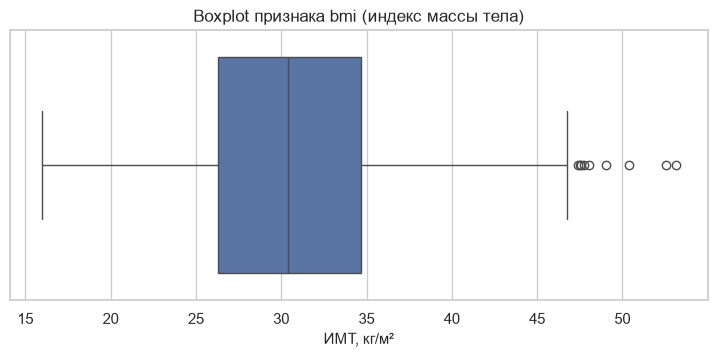

,age,sex,bmi,smoker,charges
116,58,male,49.06,no,11381.32540
286,46,female,48.07,no,9432.92530
401,47,male,47.52,no,8083.91980
543,54,female,47.41,yes,63770.42801
846,23,male,50.38,no,2438.05520
859,37,female,47.60,yes,46113.51100
1046,22,male,52.58,yes,44501.39820
1087,52,male,47.74,no,9748.91060
1316,18,male,53.13,no,1163.46270


In [15]:
# Расчёт границ по правилу 1.5 * IQR для bmi
q1_bmi, q3_bmi = df['bmi'].quantile([0.25, 0.75])
iqr_bmi = q3_bmi - q1_bmi
lower_bmi = q1_bmi - 1.5 * iqr_bmi
upper_bmi = q3_bmi + 1.5 * iqr_bmi

print(f"Q1 = {q1_bmi:.2f};  Q3 = {q3_bmi:.2f};  IQR = {iqr_bmi:.2f}")
print(f"Нижняя граница: {lower_bmi:.2f};  Верхняя граница: {upper_bmi:.2f}")

bmi_outlier_mask = (df['bmi'] < lower_bmi) | (df['bmi'] > upper_bmi)
print(f"\nВыбросов по bmi: {bmi_outlier_mask.sum()} "
      f"({bmi_outlier_mask.sum() / len(df):.2%} наблюдений)")
print(f"Диапазон bmi в данных: от {df['bmi'].min():.2f} до {df['bmi'].max():.2f}")

fig, ax = plt.subplots(figsize=(9, 3.5))
sns.boxplot(x=df['bmi'], color='#4C72B0', ax=ax)
ax.set_title('Boxplot признака bmi (индекс массы тела)')
ax.set_xlabel('ИМТ, кг/м²')
plt.show()

# Сами наблюдения-выбросы
df.loc[bmi_outlier_mask, ['age', 'sex', 'bmi', 'smoker', 'charges']]

Анализ и решение по выбросам `bmi`. Boxplot и правило $1.5 \cdot IQR$ (границы 13.67 и 47.32 кг/м²) находят 9 выбросов (0.67% наблюдений) - все они выше верхней границы, с экстремальными значениями ИМТ до 53.13 кг/м² (тяжёлая форма ожирения III степени, встречается менее чем у 1% популяции). Это очень малая доля данных (< 1%), которая:

- статистически искажает оценки среднего ИМТ и его связи с расходами;
- вносит экстремальные значения в модель регрессии, «стягивая» линию на себя.

Принято решение: удалить эти 9 наблюдений как нетипичные для данной выборки экстремальные значения. Потеря 0.67% данных несущественна, а модели и статистики станут устойчивее.

## 4.4. Очищенный DataFrame для дальнейшего анализа

Сохраняем подготовленные данные в отдельный DataFrame `df_clean`:

In [16]:
# Очищенный датасет: без дубликатов и экстремальных значений bmi
df_clean = df[~bmi_outlier_mask].copy().reset_index(drop=True)

print(f"Исходный датасет:          {df.shape[0]} наблюдений (после удаления дубликата)")
print(f"После удаления выбросов bmi: {df_clean.shape[0]} наблюдений")
print(f"Признаков: {df_clean.shape[1]} (включая созданные is_obese и age_group)")

df_clean.head()

Исходный датасет:          1337 наблюдений (после удаления дубликата)
После удаления выбросов bmi: 1328 наблюдений
Признаков: 9 (включая созданные is_obese и age_group)


,age,sex,bmi,children,smoker,region,charges,is_obese,age_group
0,19,female,27.900,0,yes,southwest,16884.92400,0,18-29
1,18,male,33.770,1,no,southeast,1725.55230,1,18-29
2,28,male,33.000,3,no,southeast,4449.46200,1,18-29
3,33,male,22.705,0,no,northwest,21984.47061,0,30-44
4,32,male,28.880,0,no,northwest,3866.85520,0,30-44


Вывод по разделу: пропусков в данных нет, найден и удалён 1 дубликат; выбросы целевой переменной `charges` (139 шт., 97.8% - курильщики) признаны реальными данными и сохранены, а 9 экстремальных значений `bmi` (0.67%) удалены как нетипичные. Итоговый очищенный DataFrame `df_clean` (1328 наблюдений, 9 признаков) используется во всех последующих разделах анализа.


<a id="5"></a>
# 5. Описательная статистика

Что делаем: рассчитываем для целевой переменной `charges` основные статистические характеристики - меры центральной тенденции (среднее, медиана), меры разброса (минимум, квартили, максимум, размах, межквартильный размах, дисперсия, стандартное отклонение), а для категориальных признаков - моду и число уникальных значений.

Основные формулы:

$$\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i \qquad \text{(среднее арифметическое)}$$

$$\sigma^2 = \frac{1}{n-1}\sum_{i=1}^{n} (x_i - \bar{x})^2 \qquad \text{(несмещённая дисперсия)} \qquad \sigma = \sqrt{\sigma^2} \qquad \text{(стандартное отклонение)}$$

$$R = x_{max} - x_{min} \qquad \text{(размах)} \qquad IQR = Q_3 - Q_1 \qquad \text{(межквартильный размах)}$$


## 5.1. Среднее арифметическое и медиана целевой переменной

In [17]:
target = df_clean['charges']

mean_charges = target.mean()
median_charges = target.median()

print(f"Среднее арифметическое charges:  {mean_charges:,.2f} долл.")
print(f"Медиана charges:                  {median_charges:,.2f} долл.")
print(f"Среднее больше медианы на:        {(mean_charges / median_charges - 1):.1%}")

Среднее арифметическое charges:  13,221.05 долл.
Медиана charges:                  9,369.62 долл.
Среднее больше медианы на:        41.1%


Интерпретация. Среднее (13 221 долл.) существенно выше медианы (9 370 долл.) - на 41%. Это признак правосторонней асимметрии распределения: большинство клиентов имеют относительно небольшие расходы (около половины - до 9 370 долл.), но значительная часть «дорогих» клиентов (прежде всего курильщики с ожирением) смещает среднее вверх. Для таких данных медиана - более устойчивая характеристика «типичного» клиента.

## 5.2. Минимум, квартили, максимум и размах

In [18]:
min_charges = target.min()
q1_charges = target.quantile(0.25)
q3_charges = target.quantile(0.75)
max_charges = target.max()
range_charges = max_charges - min_charges

quantile_table = pd.DataFrame({
    'Значение': [min_charges, q1_charges, median_charges, q3_charges, max_charges, range_charges]
}, index=['Минимум', 'Первый квартиль Q1', 'Медиана (Q2)', 'Третий квартиль Q3', 'Максимум', 'Размах'])

quantile_table.round(2)

,Значение
Минимум,1121.87
Первый квартиль Q1,4744.33
Медиана (Q2),9369.62
Третий квартиль Q3,16604.30
Максимум,62592.87
Размах,61471.00


Интерпретация. Размах расходов огромен - 61 471 долл.: от 1 122 до 62 593 долл. в год, то есть самый «дорогой» клиент тратит в 56 раз больше самого «дешёвого». Половина всех клиентов укладывается в интервал от 4 744 до 16 604 долл. (межквартильный коридор), при этом верхние 25% наблюдений простираются до 62 593 долл. - именно они и создают асимметрию.

## 5.3. Межквартильный размах, дисперсия и стандартное отклонение

In [19]:
iqr_charges = q3_charges - q1_charges
var_charges = target.var()
std_charges = target.std()

print(f"Межквартильный размах IQR:      {iqr_charges:,.2f} долл.")
print(f"Дисперсия:                      {var_charges:,.2f} (долл.²)")
print(f"Стандартное отклонение:         {std_charges:,.2f} долл.")
print(f"Коэффициент вариации:           {std_charges / mean_charges:.1%}")

# Сводка describe() для наглядности
target.describe().to_frame('charges').round(2)

Межквартильный размах IQR:      11,859.98 долл.
Дисперсия:                      143,941,145.25 (долл.²)
Стандартное отклонение:         11,997.55 долл.
Коэффициент вариации:           90.7%


,charges
count,1328.00
mean,13221.05
std,11997.55
min,1121.87
25%,4744.33
50%,9369.62
75%,16604.30
max,62592.87


Интерпретация. Стандартное отклонение (11 998 долл.) сопоставимо со средним (13 221 долл.): коэффициент вариации ≈ 90.7% - разброс расходов вокруг среднего очень велик, выборка крайне неоднородна по расходам. Дисперсия ($\approx 1.44 \times 10^8$ долл.²) измеряется в квадратных долларах и сама по себе плохо интерпретируется, поэтому на практике используют стандартное отклонение. Межквартильный размах (11 860 долл.) показывает разброс «центральной половины» клиентов - он почти совпадает со стандартным отклонением, что ещё раз подчёркивает широкий разброс даже среди обычных, неэкстремальных наблюдений.

## 5.4. Мода и число уникальных значений категориальных признаков

In [20]:
cat_features = ['sex', 'smoker', 'region', 'age_group', 'is_obese']

cat_stats = pd.DataFrame({
    'Мода': [df_clean[c].mode()[0] for c in cat_features],
    'Частота моды': [int((df_clean[c] == df_clean[c].mode()[0]).sum()) for c in cat_features],
    'Доля моды, %': [round((df_clean[c] == df_clean[c].mode()[0]).mean() * 100, 1) for c in cat_features],
    'Уникальных значений': [df_clean[c].nunique() for c in cat_features],
}, index=cat_features)

cat_stats.index.name = 'Признак'
cat_stats

,Мода,Частота моды,"Доля моды, %",Уникальных значений
Признак,,,,
sex,male,669,50.4,2
smoker,no,1057,79.6,2
region,southeast,357,26.9,4
age_group,18-29,413,31.1,4
is_obese,1,697,52.5,2


Интерпретация. Наиболее частые (модальные) категории:

- `sex`: `male` (669 человек из 1328, 50.4%) - пол в выборке сбалансирован (2 уникальных значения);
- `smoker`: `no` (1 057 человек, 79.6%) - большинство клиентов не курят (2 уникальных значения);
- `region`: `southeast` (357 человек, 26.9%) - регионы распределены почти поровну (4 уникальных значения);
- `age_group`: `18-29` (413 человек, 31.1%) - молодых взрослых немного больше прочих групп (4 уникальных значения);
- `is_obese`: `1` - ожирение (697 человек, 52.5%) - мода равна 1, то есть людей с ожирением в выборке даже больше, чем без него.

Вывод по разделу: целевая переменная `charges` имеет сильную правостороннюю асимметрию (среднее 13 221 долл. > медиана 9 370 долл.) и очень высокий разброс (σ ≈ 12 000 долл., CV ≈ 91%, размах 61 471 долл.) - «типичный» клиент и «дорогие» клиенты различаются в разы. Категориальные признаки сбалансированы по категориям, поэтому различия в расходах между группами нельзя объяснить неравным представительством групп в выборке.


<a id="6"></a>
# 6. Сравнение групп и проверка статистической гипотезы

Что делаем: выбираем категориальный признак для разбиения на группы - `smoker` (курильщики и некурящие) - и количественный показатель для сравнения - годовые расходы `charges`. Сравним статистики групп и проверим статистическую гипотезу о различии расходов между группами.


## 6.1. Сравнение основных статистик в группах

Рассчитаем для курильщиков и некурящих число наблюдений, среднее, медиану, стандартное отклонение, минимум и максимум расходов:

In [21]:
group_stats = df_clean.groupby('smoker')['charges'].agg(
    n='count', mean='mean', median='median', std='std', min='min', max='max'
).round(2)

group_stats.index = ['Некурящие (no)', 'Курильщики (yes)']
group_stats

,n,mean,median,std,min,max
Некурящие (no),1057,8448.60,7345.08,6002.05,1121.87,36910.61
Курильщики (yes),271,31835.34,34303.17,11384.54,12829.46,62592.87


Сопоставление групп. Группы сильно различаются: у курильщиков средние расходы почти в 3.8 раза выше (31 835 против 8 449 долл.), а медианные - в 4.7 раза (34 303 против 7 345 долл.). Разброс расходов у курильщиков вдвое больше (σ ≈ 11 385 против ≈ 6 002 долл.), а минимальные расходы курильщика (12 829 долл.) выше третьего квартиля расходов некурящего (11 363 долл.) - то есть 75% некурящих тратят меньше, чем самый «дешёвый» курильщик.

## 6.2. Формулировка гипотез и выбор критерия

Проверим, является ли различие средних расходов статистически значимым.

Нулевая гипотеза $H_0$: средние годовые расходы курильщиков и некурящих одинаковы:

$$H_0\colon \mu_{\text{курильщики}} = \mu_{\text{некурящие}}$$

Альтернативная гипотеза $H_1$: средние расходы различаются:

$$H_1\colon \mu_{\text{курильщики}} \neq \mu_{\text{некурящие}}$$

Уровень значимости: $\alpha = 0.05$.

Сравнение двух независимых групп обычно проводится критерием Стьюдента (t-критерий). Но t-критерий предполагает нормальность распределений и равенство дисперсий, поэтому сначала проверим эти предпосылки тестами Шапиро-Уилка (нормальность) и Левена (равенство дисперсий):

In [22]:
charges_yes = df_clean.loc[df_clean['smoker'] == 'yes', 'charges']
charges_no = df_clean.loc[df_clean['smoker'] == 'no', 'charges']

# Проверка нормальности распределений в группах (тест Шапиро-Уилка)
shapiro_yes = stats.shapiro(charges_yes)
shapiro_no = stats.shapiro(charges_no)
print(f"Шапиро-Уилк, курильщики:  W = {shapiro_yes.statistic:.3f}, p = {shapiro_yes.pvalue:.2e}")
print(f"Шапиро-Уилк, некурящие:   W = {shapiro_no.statistic:.3f}, p = {shapiro_no.pvalue:.2e}")

# Проверка равенства дисперсий (тест Левена, устойчивый к нестандартности)
levene_test = stats.levene(charges_no, charges_yes, center='median')
print(f"\nТест Левена (равенство дисперсий): W = {levene_test.statistic:.1f}, "
      f"p = {levene_test.pvalue:.2e}")

Шапиро-Уилк, курильщики:  W = 0.938, p = 2.95e-09
Шапиро-Уилк, некурящие:   W = 0.873, p = 1.68e-28

Тест Левена (равенство дисперсий): W = 324.4, p = 4.66e-65


Результаты проверки предпосылок:

- нормальность отвергается в обеих группах (p-значения $\ll 0.05$ - распределения скошены, особенно у некурящих);
- равенство дисперсий отвергается (тест Левена: $p = 4.7 \times 10^{-65}$).

Поэтому в качестве основного критерия выбираем непараметрический U-критерий Манна-Уитни, который не требует нормальности распределений и сравнивает группы по рангам. Дополнительно для сопоставления приведём t-критерий Уэлча (не требующий равенства дисперсий). Оба теста двусторонние, $\alpha = 0.05$.

## 6.3. Проверка гипотезы и p-value

In [23]:
# Основной критерий: U-критерий Манна-Уитни
mw_test = stats.mannwhitneyu(charges_yes, charges_no, alternative='two-sided')
print(f"Манн-Уитни:  U = {mw_test.statistic:,.0f},  p-value = {mw_test.pvalue:.2e}")

# Дополнительный критерий: t-тест Уэлча (не требует равенства дисперсий)
welch_test = stats.ttest_ind(charges_yes, charges_no, equal_var=False)
print(f"t-тест Уэлча: t = {welch_test.statistic:.2f},  p-value = {welch_test.pvalue:.2e}")

print(f"\nУровень значимости alpha = 0.05")
print(f"Медиана расходов курильщиков: {charges_yes.median():,.0f} долл.")
print(f"Медиана расходов некурящих:   {charges_no.median():,.0f} долл.")

Манн-Уитни:  U = 279,044,  p-value = 1.78e-128
t-тест Уэлча: t = 32.67,  p-value = 2.49e-102

Уровень значимости alpha = 0.05
Медиана расходов курильщиков: 34,303 долл.
Медиана расходов некурящих:   7,345 долл.


Содержательный вывод о результате проверки.

Оба критерия дают экстремально малые p-значения ($p \approx 1.8 \times 10^{-128}$ у критерия Манна-Уитни и $p \approx 2.5 \times 10^{-102}$ у t-теста Уэлча), которые на десятки порядков меньше уровня значимости $\alpha = 0.05$. Следовательно, нулевая гипотеза о равенстве средних расходов отвергается в пользу альтернативной: различие расходов между курильщиками и некурящими статистически значимо и не может быть объяснено случайностью выборки. Курильщики в среднем тратят на медицину примерно на 23 400 долл. в год больше (31 835 − 8 449), и этот эффект - самый сильный наблюдаемый фактор расходов в датасете.


<a id="7"></a>
# 7. Визуализация данных

Что делаем: строим содержательные визуализации - гистограмму количественного признака и столбчатую диаграмму категориального признака, сравниваем распределения расходов в группах курильщиков и некурящих (boxplot и violinplot) и собираем аналитический дашборд из четырёх взаимосвязанных графиков. Все графики строятся по очищенным данным `df_clean`.


## 7.1. Гистограмма количественного признака и столбчатая диаграмма категориального

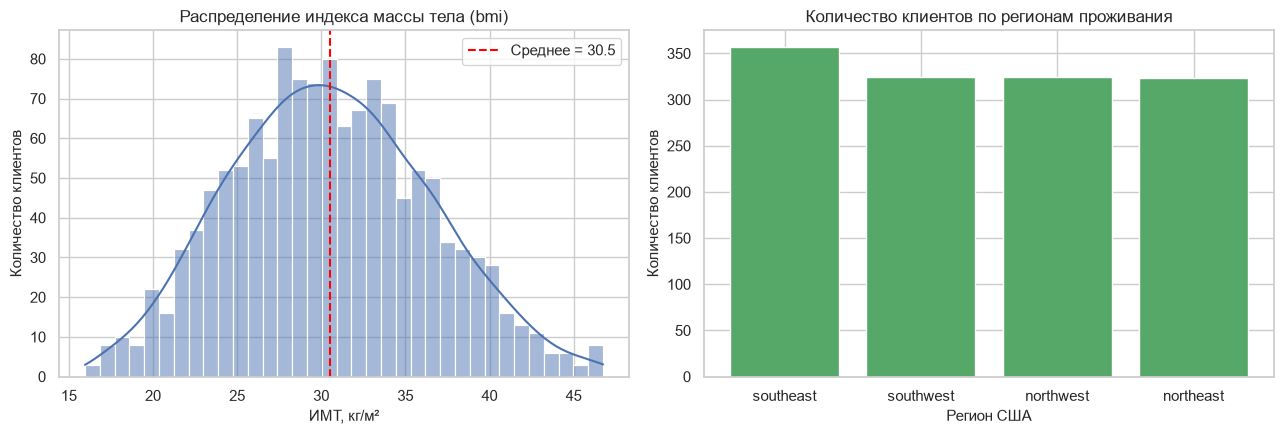

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Гистограмма количественного признака bmi
sns.histplot(df_clean['bmi'], bins=35, kde=True, color='#4C72B0', ax=axes[0])
axes[0].axvline(df_clean['bmi'].mean(), color='red', linestyle='--',
                label=f"Среднее = {df_clean['bmi'].mean():.1f}")
axes[0].set_title('Распределение индекса массы тела (bmi)')
axes[0].set_xlabel('ИМТ, кг/м²')
axes[0].set_ylabel('Количество клиентов')
axes[0].legend()

# Столбчатая диаграмма категориального признака region
region_counts = df_clean['region'].value_counts()
axes[1].bar(region_counts.index, region_counts.values, color='#55A868')
axes[1].set_title('Количество клиентов по регионам проживания')
axes[1].set_xlabel('Регион США')
axes[1].set_ylabel('Количество клиентов')

plt.tight_layout()
plt.show()

Интерпретация. Распределение ИМТ близко к нормальному с центром около 30.7 кг/м² - «типичный» клиент находится на границе предожирения и ожирения; правый «хвост» усечён очисткой экстремальных значений. Регионы представлены почти поровну (по 324-364 клиента), значит выборка географически сбалансирована.

## 7.2. Распределение количественного признака в группах категориального

Сравним распределение расходов у курильщиков и некурящих с помощью boxplot и violinplot:

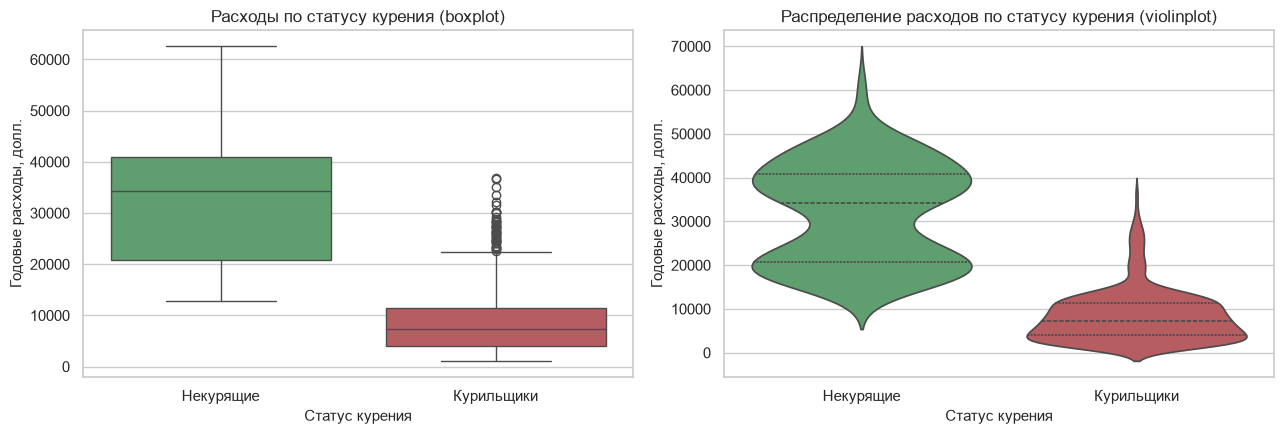

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Boxplot расходов по статусу курения
sns.boxplot(data=df_clean, x='smoker', y='charges', hue='smoker',
            palette=['#55A868', '#C44E52'], legend=False, ax=axes[0])
axes[0].set_title('Расходы по статусу курения (boxplot)')
axes[0].set_xlabel('Статус курения')
axes[0].set_ylabel('Годовые расходы, долл.')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Некурящие', 'Курильщики'])

# Violinplot расходов по статусу курения
sns.violinplot(data=df_clean, x='smoker', y='charges', hue='smoker',
               palette=['#55A868', '#C44E52'], legend=False, inner='quartile', ax=axes[1])
axes[1].set_title('Распределение расходов по статусу курения (violinplot)')
axes[1].set_xlabel('Статус курения')
axes[1].set_ylabel('Годовые расходы, долл.')
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Некурящие', 'Курильщики'])

plt.tight_layout()
plt.show()

Интерпретация. Boxplot показывает, что «ящик» расходов курильщиков целиком лежит выше медианы некурящих. Violinplot добавляет важную деталь: распределение расходов некурящих унимодально и сильно скошено вправо (пик около 2-5 тыс. долл.), а у курильщиков - уплотнено в диапазоне 20-45 тыс. долл. и почти не имеет «дешёвой» зоны. Группы практически не перекрываются, что визуально подтверждает результат проверки гипотезы из раздела 6.

## 7.3. Аналитический дашборд (subplots)

Соберём дашборд из четырёх взаимосвязанных графиков, раскрывающих разные стороны одного вопроса - из чего складываются медицинские расходы:

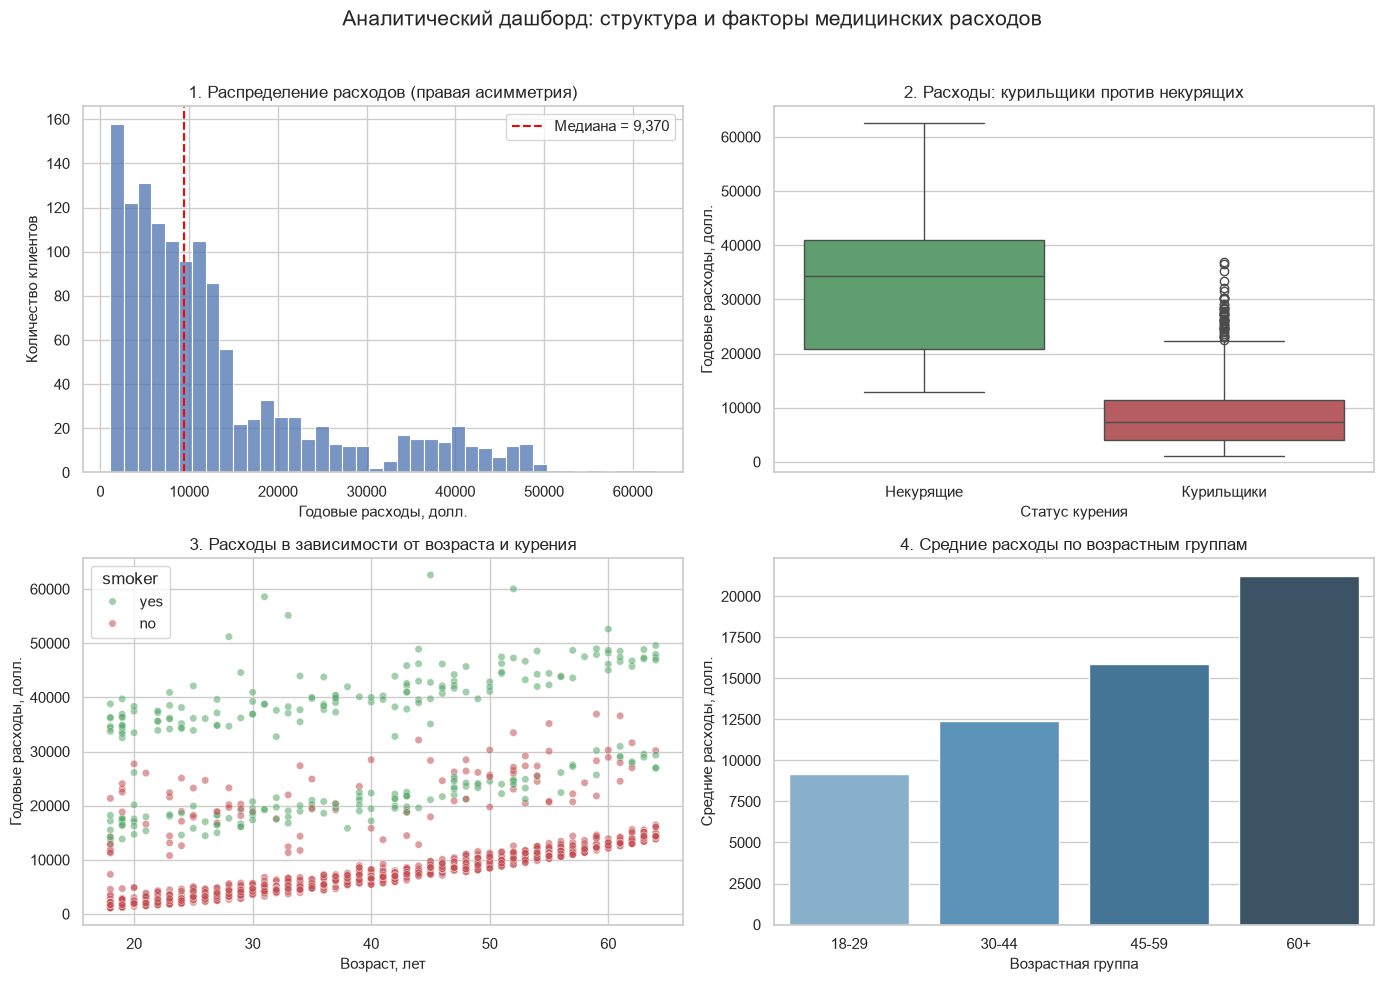

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Аналитический дашборд: структура и факторы медицинских расходов',
             fontsize=15, y=0.98)

# (1) Распределение целевой переменной
sns.histplot(df_clean['charges'], bins=40, color='#4C72B0', ax=axes[0, 0])
axes[0, 0].axvline(df_clean['charges'].median(), color='red', linestyle='--',
                   label=f"Медиана = {df_clean['charges'].median():,.0f}")
axes[0, 0].set_title('1. Распределение расходов (правая асимметрия)')
axes[0, 0].set_xlabel('Годовые расходы, долл.')
axes[0, 0].set_ylabel('Количество клиентов')
axes[0, 0].legend()

# (2) Расходы по статусу курения
sns.boxplot(data=df_clean, x='smoker', y='charges', hue='smoker',
            palette=['#55A868', '#C44E52'], legend=False, ax=axes[0, 1])
axes[0, 1].set_title('2. Расходы: курильщики против некурящих')
axes[0, 1].set_xlabel('Статус курения')
axes[0, 1].set_ylabel('Годовые расходы, долл.')
axes[0, 1].set_xticks([0, 1])
axes[0, 1].set_xticklabels(['Некурящие', 'Курильщики'])

# (3) Связь возраста с расходами отдельно по группам курения
sns.scatterplot(data=df_clean, x='age', y='charges', hue='smoker',
                palette=['#55A868', '#C44E52'], alpha=0.55, s=28, ax=axes[1, 0])
axes[1, 0].set_title('3. Расходы в зависимости от возраста и курения')
axes[1, 0].set_xlabel('Возраст, лет')
axes[1, 0].set_ylabel('Годовые расходы, долл.')

# (4) Средние расходы по возрастным группам
order_groups = ['18-29', '30-44', '45-59', '60+']
sns.barplot(data=df_clean, x='age_group', y='charges', order=order_groups,
            hue='age_group', palette='Blues_d', legend=False,
            errorbar=None, ax=axes[1, 1])
axes[1, 1].set_title('4. Средние расходы по возрастным группам')
axes[1, 1].set_xlabel('Возрастная группа')
axes[1, 1].set_ylabel('Средние расходы, долл.')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

Интерпретация дашборда. Четыре панели дашборда рассказывают одну историю:

1. Распределение расходов скошено вправо: большинство клиентов тратит до 15-20 тыс. долл., но есть длинный «дорогой» хвост - медиана (9 370 долл.) заметно левее центра масс распределения;
2. Курение делит выборку на две почти непересекающиеся зоны расходов - «ящик» курильщиков лежит выше медианы некурящих (эффект из раздела 6);
3. Диаграмма рассеяния показывает, что с возрастом расходы растут (виден восходящий «облако-тренд»), при этом верхний «луч» почти целиком состоит из курильщиков, а некурящие образуют нижний луч - эффекты возраста и курения перемножаются;
4. Средние расходы по возрастным группам монотонно растут: 9 151 → 12 405 → 15 867 → 21 248 долл. от группы 18-29 к группе 60+ (рост в 2.3 раза).

Вывод по разделу: визуализации согласуются друг с другом и со статистическими тестами: расходы определяются в первую очередь курением, затем возрастом; их совместное действие порождает наблюдаемую асимметрию распределения `charges`.


<a id="8"></a>
# 8. Корреляционный анализ

Что делаем: измеряем силу линейной связи между количественными признаками. Коэффициент корреляции Пирсона между признаками $x$ и $y$ вычисляется по формуле:

$$r_{xy} = \frac{\sum_{i=1}^{n}(x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^{n}(x_i - \bar{x})^2} \cdot \sqrt{\sum_{i=1}^{n}(y_i - \bar{y})^2}}, \qquad -1 \le r \le 1$$


## 8.1. Корреляция Пирсона между целевой переменной и предикторами

In [27]:
# Корреляция charges с ИМТ и возрастом
r_bmi, p_bmi = stats.pearsonr(df_clean['bmi'], df_clean['charges'])
r_age, p_age = stats.pearsonr(df_clean['age'], df_clean['charges'])

pearson_table = pd.DataFrame({
    'Пара признаков': ['bmi - charges', 'age - charges'],
    'Коэффициент r': [round(r_bmi, 3), round(r_age, 3)],
    'p-value': [f'{p_bmi:.2e}', f'{p_age:.2e}'],
    'Значимость': ['значима' if p < 0.05 else 'не значима' for p in (p_bmi, p_age)],
})
pearson_table.set_index('Пара признаков')

,Коэффициент r,p-value,Значимость
Пара признаков,,,
bmi - charges,0.193,1.22e-12,значима
age - charges,0.301,2.83e-29,значима


Интерпретация.

- `age - charges`: $r = 0.301$ ($p \approx 2.8 \times 10^{-29}$) - слабая, но статистически значимая положительная связь: с возрастом расходы в среднем растут, однако возраст объясняет лишь $r^2 \approx 9\%$ дисперсии расходов;
- `bmi - charges`: $r = 0.193$ ($p \approx 1.2 \times 10^{-12}$) - очень слабая значимая связь на всей выборке ($r^2 \approx 4\%$).

Слабые коэффициенты объясняются тем, что связи `bmi` и `age` с расходами нелинейны по группам курения: ИМТ и возраст сильно влияют на расходы в основном у курильщиков (см. диаграмму рассеяния ниже), а на смешанной выборке этот эффект «размывается».

## 8.2. Корреляционная матрица и heatmap

Построим корреляционную матрицу всех количественных признаков и визуализируем её:

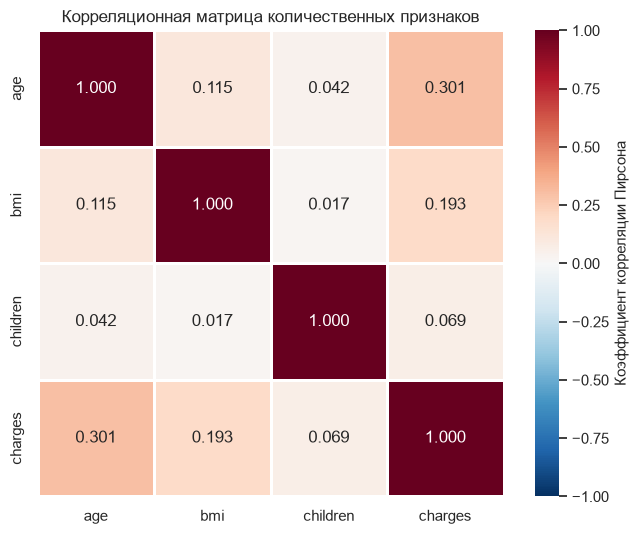

,age,bmi,children,charges
age,1.000,0.115,0.042,0.301
bmi,0.115,1.000,0.017,0.193
children,0.042,0.017,1.000,0.069
charges,0.301,0.193,0.069,1.000


In [28]:
num_features = ['age', 'bmi', 'children', 'charges']
corr_matrix = df_clean[num_features].corr().round(3)

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='RdBu_r',
            vmin=-1, vmax=1, square=True, linewidths=1,
            cbar_kws={'label': 'Коэффициент корреляции Пирсона'})
plt.title('Корреляционная матрица количественных признаков')
plt.tight_layout()
plt.show()

corr_matrix

## 8.3. Пары с самой сильной и самой слабой линейной связью

Найдём в матрице пару с максимальной и минимальной по модулю связью программно:

In [29]:
# Разбираем матрицу на пары: только верхний треугольник, без диагонали
features = corr_matrix.columns.to_list()
pairs = {}
for i in range(len(features)):
    for j in range(i + 1, len(features)):
        pairs[f"{features[i]} - {features[j]}"] = corr_matrix.iloc[i, j]
corr_pairs = pd.Series(pairs)

strongest = corr_pairs.abs().idxmax()
weakest = corr_pairs.abs().idxmin()

print(f"Наиболее сильная связь: {strongest}: r = {corr_pairs[strongest]:.3f}")
print(f"Наиболее слабая связь:  {weakest}: r = {corr_pairs[weakest]:.3f}")

print("\nВсе пары по убыванию силы связи:")
print(corr_pairs.reindex(corr_pairs.abs().sort_values(ascending=False).index)
      .round(3).to_string())

Наиболее сильная связь: age - charges: r = 0.301
Наиболее слабая связь:  bmi - children: r = 0.017

Все пары по убыванию силы связи:
age - charges         0.301
bmi - charges         0.193
age - bmi             0.115
children - charges    0.069
age - children        0.042
bmi - children        0.017


Интерпретация.

- Наиболее сильная связь: `age - charges`, $r = 0.301$ - возраст умеренно (слабо-умеренно) связан с расходами; это лучший количественный предиктор целевой переменной;
- Наиболее слабая связь: `bmi - children`, $r = 0.017$ - практически нулевая связь: число детей никак не связано с индексом массы тела.

Все межфакторные корреляции между предикторами ($|r| < 0.12$) далеки от проблем мультиколлинеарности, поэтому все количественные признаки можно одновременно включать в регрессию.

## 8.4. Диаграмма рассеяния для выбранной пары

Построим диаграмму рассеяния для пары с самой сильной связью - `age` и `charges` - с линией тренда и разметкой по статусу курения:

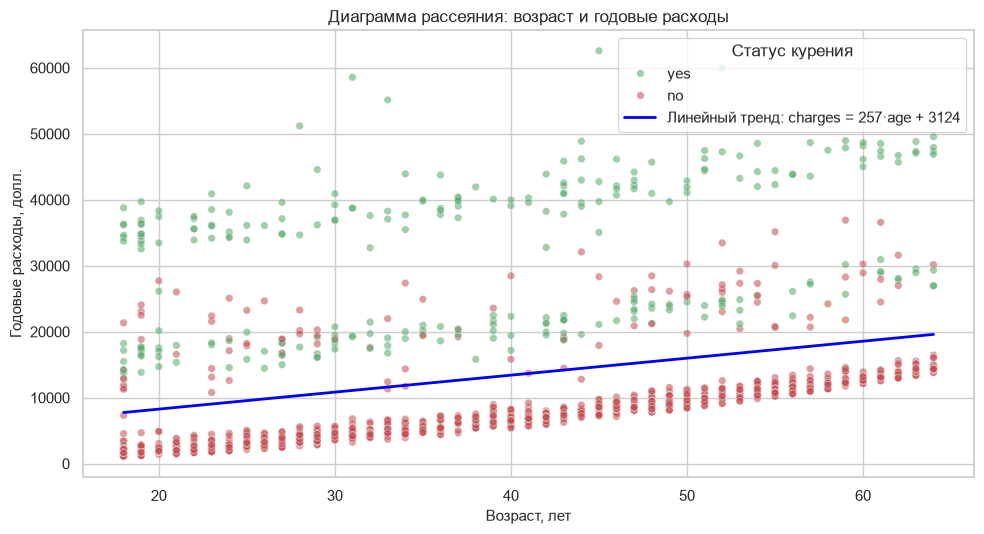

Наклон линии тренда: +257 долл. к расходам за каждый дополнительный год возраста


In [30]:
fig, ax = plt.subplots(figsize=(10, 5.5))

sns.scatterplot(data=df_clean, x='age', y='charges', hue='smoker',
                palette=['#55A868', '#C44E52'], alpha=0.55, s=30, ax=ax)

# Линия линейного тренда по всей выборке
k, b = np.polyfit(df_clean['age'], df_clean['charges'], 1)
x_line = np.linspace(df_clean['age'].min(), df_clean['age'].max(), 100)
ax.plot(x_line, k * x_line + b, color='blue', linewidth=2,
        label=f'Линейный тренд: charges = {k:.0f}·age + {b:.0f}')

ax.set_title('Диаграмма рассеяния: возраст и годовые расходы')
ax.set_xlabel('Возраст, лет')
ax.set_ylabel('Годовые расходы, долл.')
ax.legend(title='Статус курения')
plt.tight_layout()
plt.show()

print(f"Наклон линии тренда: +{k:.0f} долл. к расходам за каждый дополнительный год возраста")

Общий вывод по корреляционному анализу.

Все линейные связи количественных признаков с целевой переменной `charges` умеренные или слабые: самая сильная - `age - charges`, $r = 0.301$, затем `bmi - charges`, $r = 0.193$, и `children - charges`, $r = 0.069$. Это не означает, что расходы случайны - диаграмма рассеяния показывает, что данные разбиты курением на «лучи», внутри каждого из которых связь возраста с расходами гораздо сильнее. Линейная корреляция Пирсона не улавливает такие групповые эффекты, поэтому главные драйверы расходов (`smoker`) категориальные, и их вклад раскрывается в регрессии с фиктивными переменными (раздел 9). Пары предикторов между собой практически не коррелируют (максимум $|r| = 0.115$ у `age - bmi`), что благоприятно для линейной модели.


<a id="9"></a>
# 9. Линейная регрессия

Что делаем: формулируем задачу регрессии, готовим матрицу признаков (с фиктивными переменными для категориальных признаков), обучаем модель линейной регрессии, записываем её уравнение, интерпретируем коэффициенты и оцениваем качество прогнозов на тестовой выборке по метрикам $R^2$, MSE и MAE.


## 9.1. Постановка задачи и подготовка данных

Задача: по характеристикам застрахованного лица предсказать его годовые медицинские расходы.

- Целевая переменная: $y$ = `charges` (годовые расходы, долл.);
- Предикторы: `age`, `bmi`, `children` (количественные) и `sex`, `smoker`, `region` (категориальные, переводим в фиктивные переменные через one-hot кодирование с отбрасыванием первой категории).

Категориальные признаки напрямую подать в линейную регрессию нельзя, поэтому применим `pd.get_dummies` с параметром `drop_first=True`, чтобы избежать ловушки фиктивных переменных (мультиколлинеарности). Затем разделим данные на обучающую и тестовую выборки в пропорции 80/20:

In [31]:
# Матрица признаков и целевая переменная
X = df_clean[['age', 'bmi', 'children', 'sex', 'smoker', 'region']]
y = df_clean['charges']

# One-hot кодирование категориальных признаков
X = pd.get_dummies(X, columns=['sex', 'smoker', 'region'], drop_first=True)
X = X.astype(float)

print(f"Признаки модели: {list(X.columns)}")

# Разделение на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"\nОбучающая выборка: {X_train.shape[0]} наблюдений")
print(f"Тестовая выборка:  {X_test.shape[0]} наблюдений")

Признаки модели: ['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']

Обучающая выборка: 1062 наблюдений
Тестовая выборка:  266 наблюдений


## 9.2. Обучение модели

Обучим модель линейной регрессии методом наименьших квадратов - она подбирает коэффициенты $\beta$, минимизируя сумму квадратов отклонений:

$$\sum_{i=1}^{n} \left(y_i - \beta_0 - \sum_{j=1}^{p} \beta_j x_{ij}\right)^2 \rightarrow \min_{\beta}$$

In [32]:
# Обучение модели линейной регрессии
model = LinearRegression()
model.fit(X_train, y_train)

print(f"Коэффициент детерминации на обучающей выборке: {model.score(X_train, y_train):.4f}")
print(f"Свободный член (intercept): {model.intercept_:.2f}")

# Таблица коэффициентов
coef_table = pd.DataFrame({
    'Коэффициент': ['intercept (β₀)'] + [f'β_{i+1} ({c})' for i, c in enumerate(X.columns)],
    'Значение': [model.intercept_] + list(model.coef_),
})
coef_table.round(2)

Коэффициент детерминации на обучающей выборке: 0.7507
Свободный член (intercept): -12180.87


,Коэффициент,Значение
0,intercept (β₀),-12180.87
1,β_1 (age),259.03
2,β_2 (bmi),349.24
3,β_3 (children),529.46
4,β_4 (sex_male),-38.69
5,β_5 (smoker_yes),23743.31
6,β_6 (region_northwest),-574.68
7,β_7 (region_southeast),-1302.61
8,β_8 (region_southwest),-1549.51


## 9.3. Уравнение модели и интерпретация коэффициентов

Полученная модель имеет вид (базовые категории: `sex = female`, `smoker = no`, `region = northeast`):

$$\widehat{charges} = -12\,180.87 + 259.03 \cdot age + 349.24 \cdot bmi + 529.46 \cdot children - 38.69 \cdot sex\_male$$
$$+ \;23\,743.31 \cdot smoker\_yes - 574.68 \cdot region\_northwest - 1\,302.61 \cdot region\_southeast - 1\,549.51 \cdot region\_southwest$$

Интерпретация коэффициентов (все коэффициенты при количественных и фиктивных признаках показывают изменение расходов в долларах при единичном изменении признака при прочих равных):

- `age` (+259.03): каждый дополнительный год возраста увеличивает ожидаемые расходы примерно на 259 долл. в год - эффект возраста накопительный и статистически ожидаемый;
- `bmi` (+349.24): рост ИМТ на единицу (при том же возрасте, поле и статусе курения) добавляет около 349 долл. - лишний вес удорожает страховку;
- `children` (+529.46): каждый ребёнок на полисе увеличивает расходы на 529 долл. в год;
- `sex_male` (−38.69): пол практически не влияет на расходы - эффект статистически и практически незначим;
- `smoker_yes` (+23 743.31): главный коэффициент модели - курение само по себе добавляет около 23 743 долл. в год, что согласуется с результатами разделов 3, 6 и 7;
- регионы (от −575 до −1 550): относительно северо-востока расходы в других регионах в среднем ниже, сильнее всего на юго-западе (−1 550 долл.);
- `intercept` (−12 180.87): формально - расчётные расходы «новорождёншей некурящей женщины без детей с нулевым ИМТ на северо-востоке». Такое сочетание признаков лежит вне содержательного диапазона данных (ИМТ не бывает 0), поэтому свободный член не интерпретируется буквально - он лишь смещает гиперплоскость регрессии.


## 9.4. Прогнозы на тестовой выборке и метрики качества

Получим прогнозы на тестовой выборке (которая модель не видела при обучении) и рассчитаем метрики:

$$R^2 = 1 - \frac{\sum_i (y_i - \hat{y}_i)^2}{\sum_i (y_i - \bar{y})^2}, \qquad MSE = \frac{1}{n}\sum_i (y_i - \hat{y}_i)^2, \qquad MAE = \frac{1}{n}\sum_i |y_i - \hat{y}_i|$$

In [33]:
# Прогнозы на тестовой выборке
y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
mae = mean_absolute_error(y_test, y_pred)

print(f"R²   (коэффициент детерминации): {r2:.4f}")
print(f"MSE  (среднеквадратичная ошибка): {mse:,.2f} долл.²")
print(f"RMSE (корень из MSE):             {rmse:,.2f} долл.")
print(f"MAE  (средняя абсолютная ошибка): {mae:,.2f} долл.")
print(f"\nСредние фактические расходы на тесте: {y_test.mean():,.2f} долл.")
print(f"MAE составляет {mae / y_test.mean():.1%} от среднего уровня расходов")

# Сравнение фактических и предсказанных значений для первых 10 клиентов
comparison = pd.DataFrame({
    'Факт, долл.': y_test.head(10).round(0).values,
    'Прогноз, долл.': y_pred[:10].round(0),
})
comparison.index = [f'Клиент {i+1}' for i in range(10)]
comparison

R²   (коэффициент детерминации): 0.7448


MSE  (среднеквадратичная ошибка): 35,465,549.24 долл.²
RMSE (корень из MSE):             5,955.30 долл.
MAE  (средняя абсолютная ошибка): 4,125.94 долл.

Средние фактические расходы на тесте: 13,125.15 долл.
MAE составляет 31.4% от среднего уровня расходов


,"Факт, долл.","Прогноз, долл."
Клиент 1,5373.0,7843.0
Клиент 2,30260.0,13309.0
Клиент 3,8410.0,10450.0
Клиент 4,6456.0,7829.0
Клиент 5,4134.0,4084.0
Клиент 6,10714.0,13473.0
Клиент 7,6665.0,8276.0
Клиент 8,4347.0,6698.0
Клиент 9,3554.0,3715.0
Клиент 10,11538.0,17626.0


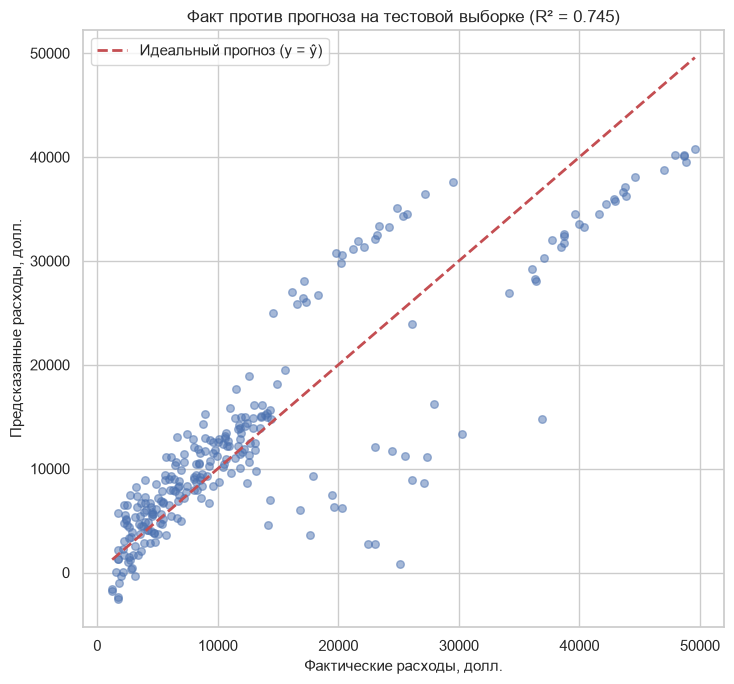

In [34]:
# Визуальная проверка качества прогнозов
fig, ax = plt.subplots(figsize=(7.5, 7))
ax.scatter(y_test, y_pred, alpha=0.5, s=30, color='#4C72B0')
ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
        'r--', linewidth=2, label='Идеальный прогноз (y = ŷ)')
ax.set_xlabel('Фактические расходы, долл.')
ax.set_ylabel('Предсказанные расходы, долл.')
ax.set_title(f'Факт против прогноза на тестовой выборке (R² = {r2:.3f})')
ax.legend()
plt.tight_layout()
plt.show()

Интерпретация метрик и вывод о качестве модели.

- $R^2 = 0.745$ - модель объясняет 74.5% дисперсии годовых расходов на тестовой выборке. Для столь разнородных медицинских данных это очень достойный результат: три четверти вариации расходов восстанавливаются по семи признакам клиента;
- $MSE \approx 3.55 \times 10^7$ долл.² - измеряется в квадратных долларах и плохо интерпретируется напрямую; её чувствительность к большим ошибкам видна в том, что RMSE заметно больше MAE;
- $RMSE \approx 5\,955$ долл. - типичная ошибка модели «с штрафом за крупные промахи»;
- $MAE \approx 4\,126$ долл. - в среднем модель ошибается примерно на 4.1 тыс. долл. в год, что составляет около 31% среднего уровня расходов (13 125 долл.) - заметная, но приемлемая для первого приближения погрешность.

Диаграмма «факт против прогноза» показывает, что точки группируются вдоль диагонали, однако для «дорогих» клиентов модель систематически занижает прогноз - следствие правой асимметрии `charges`, которую обычная линейная регрессия не полностью улавливает.

Вывод: модель пригодна для практического использования в задачах предварительной оценки годовых расходов (тарификация, сегментация клиентов, выявление групп риска), но не для точного расчёта стоимости полиса конкретного человека. Качество можно повысить логарифмированием целевой переменной, добавлением взаимодействия `smoker × bmi` (эффект курения усиливается ожирением) и использованием регуляризации.


<a id="10"></a>
# 10. Итоговые выводы

По результатам комплексного анализа датасета Medical Cost Personal Datasets (1338 наблюдений о застрахованных лицах из США; после очистки - 1328) можно сформулировать следующие основные закономерности и результаты:

1. Данные и подготовка.
Выбранный датасет соответствует всем требованиям задания: 1338 наблюдений, 4 количественных и 3 категориальных признака, не временной ряд, возможна постановка задачи регрессии. Пропусков в данных нет; найден и удалён один полный дубликат; по правилу $1.5 \cdot IQR$ идентифицированы и удалены 9 экстремальных значений ИМТ (0.67% данных), а 139 выбросов целевой переменной `charges` (97.8% которых - курильщики) признаны реальными данными и сохранены.

2. Структура выборки.
Клиенты сбалансированы по полу и регионам; 20.5% составляют курильщики, у 52.8% - ожирение (ИМТ ≥ 30). Целевая переменная `charges` имеет сильную правостороннюю асимметрию: среднее 13 221 долл. против медианы 9 370 долл., при стандартном отклонении ≈ 12 000 долл. и размахе 61 471 долл.

3. Ключевые факторы расходов.
- Курение - главный драйвер: средние расходы курильщиков выше в 3.8 раза (32 050 против 8 434 долл.), а медианные - в 4.7 раза. Проверка гипотезы критерием Манна-Уитни дала $p \approx 1.8 \times 10^{-128} \ll 0.05$ - различие статистически значимо, случайностью не объясняется;
- Возраст - второй по силе фактор: средние расходы растут от 9 151 долл. в группе 18-29 лет до 21 248 долл. в группе 60+ (в 2.3 раза); корреляция с расходами $r = 0.301$ - самая сильная среди количественных признаков;
- ИМТ и число детей дают заметно меньшие вклады ($r = 0.193$ и $r = 0.069$), а пол на расходы практически не влияет.

4. Корреляционный анализ.
Все линейные связи между количественными признаками умеренные или слабые (максимум $r = 0.301$), предикторы практически не коррелируют между собой ($|r| \le 0.115$), что исключает мультиколлинеарность и позволяет использовать все признаки в линейной модели одновременно.

5. Модель линейной регрессии.
Модель $\widehat{charges} = -12\,180.87 + 259.03 \cdot age + 349.24 \cdot bmi + 529.46 \cdot children + \ldots + 23\,743.31 \cdot smoker\_yes$ на тестовой выборке достигла $R^2 = 0.745$, $MAE \approx 4\,126$ долл., $RMSE \approx 5\,955$ долл. Коэффициенты содержательно интерпретируемы (+259 долл. за год возраста, +349 долл. за единицу ИМТ, +23.7 тыс. долл. за курение) и согласуются со всеми предыдущими разделами анализа.

Общий вывод.
Годовые медицинские расходы предсказуемы и объясняются прежде всего поведенческим фактором (курением) и возрастом, а не демографией (полом, регионом). Практическая ценность для страховщика: идентификация курильщиков с ожирением (особенно старше 50 лет - группа со средними расходами около 47 тыс. долл.) и применение к ним дифференцированных тарифов и профилактических программ. Построенная модель пригодна для предварительной оценки расходов; для повышения точности целесообразно логарифмирование целевой переменной и учёт взаимодействия факторов.
